In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from pathlib import Path
import HumSpectra.fluorescence as fl
import HumSpectra.ultraviolet as uv
import HumSpectra.utilits as ut
import HumSpectra.math_stat as st
from sklearn.decomposition import PCA
from scipy import stats

In [12]:
def add_median_labels(ax, fmt='.3f'):

    lines = ax.get_lines()
    boxes = [c for c in ax.get_children() if type(c).__name__ == 'PathPatch']
    lines_per_box = int(len(lines) / len(boxes))

    for median in lines[4:len(lines):lines_per_box]:

        x, y = (data.mean() for data in median.get_data())

        # choose value depending on horizontal or vertical plot orientation

        value = x if (median.get_xdata()[1] - median.get_xdata()[0]) == 0 else y
        text = ax.text(x, y, f'{value:{fmt}}', ha='center', va='center',
                       fontweight='bold', color='white')
        
        # create median-colored border around white text for contrast
        text.set_path_effects([
            path_effects.Stroke(linewidth=3, foreground=median.get_color()),
            path_effects.Normal(),
        ])

In [ ]:
date = "2025"
fluo_settings_list = [0,1]
iqr_setings_list = [2,2.5]
data_list = []

wdir_date = Path.cwd().parent / "Initial data" / date

uv_path = Path.joinpath(wdir_date, "UV","Individual spectra")

carbon_data = pd.read_excel(Path.joinpath(wdir_date, 'C_org.xlsx'))
geodata = pd.read_excel(Path.joinpath(wdir_date, 'GeoData.xlsx'))

uv_spectra = ut.load_spectra_data(uv_path, uv.read_csv_uv, spectra_type="reflection")

uv_data = pd.DataFrame()

uv_data["490_555"] = [uv.ratio_descriptor(uv,490,555) for uv in uv_spectra]
uv_data["412_547"] = [uv.ratio_descriptor(uv,412,547) for uv in uv_spectra]
uv_data["412_555"] = [uv.ratio_descriptor(uv,490,555) for uv in uv_spectra]
uv_data["490_555"] = [uv.ratio_descriptor(uv,490,555) for uv in uv_spectra]
uv_data["490_555"] = [uv.ratio_descriptor(uv,490,555) for uv in uv_spectra]


common_storage_list = ["Storage 2","Storage 3","Storage 4","Storage 5","Storage 6","Storage 7"]
feature_columns = ["E2E3","C_org","Suva","Asm_350","pH","Asm_280"]
feature_group_one = ["E2E3","C_org","Suva"]
feature_group_second = ["Asm_350","pH","Asm_280"]

In [14]:
uv_data = pd.read_csv(r"C:\Users\Kirill\Downloads\Telegram Desktop\disc_R.csv")
uv_data.rename(columns={uv_data.columns[0]:"Sample"},inplace=True)
uv_data["Subclass"] = uv_data.Sample.apply(lambda x: ut.extract_subclass_from_name(x))
uv_data

,Sample,r490_555,r412_547,r412_670,r412_665,r460_560,r560_705,r460_665,r525_554,r565_660,r560_655,r480_560,r280_460,Subclass
0,ADOM-SL1-1-R,0.957311,0.766345,0.733333,0.731084,0.914894,0.965092,0.879346,0.983069,0.976289,0.966084,0.940426,0.165116,Storage 1
1,ADOM-SL1-10-R,0.974645,0.883673,0.860835,0.863410,0.948223,0.989950,0.931206,0.975758,0.991968,0.985000,0.959391,0.244111,Storage 1
2,ADOM-SL1-3-R,0.924612,0.654628,0.606061,0.603538,0.843507,0.935618,0.790843,0.972191,0.954737,0.938542,0.892342,0.175000,Storage 1
3,ADOM-SL1-4-R,0.983607,0.878074,0.860442,0.863911,0.950820,0.984864,0.935484,0.987780,1.004069,0.978937,0.970287,0.375000,Storage 1
4,ADOM-SL1-5-R,0.994036,0.991045,0.986139,0.988095,0.994000,0.997009,0.986111,0.980198,1.002982,0.991080,0.985000,1.022133,Storage 1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,ADOM-SLB-B3-1-R,0.980962,0.992986,0.991000,0.990010,0.988934,1.005056,0.982018,0.985015,1.011078,0.994000,0.985915,1.041709,Baikal
111,ADOM-SLB-B3-2-R,0.984733,0.943662,0.920100,0.916667,0.964286,0.986164,0.940299,0.992376,0.992472,0.978777,0.975765,0.473545,Baikal
112,ADOM-SLB-B3-3-R,1.002014,1.000000,0.995976,0.992979,1.004044,1.005081,0.995988,0.997998,1.000000,0.991976,0.992922,0.994965,Baikal
113,ADOM-SLB-BO-2-R,0.980117,0.980047,0.955378,0.957569,0.960280,0.995349,0.942661,0.970862,0.991898,0.988453,0.964953,0.753041,Baikal


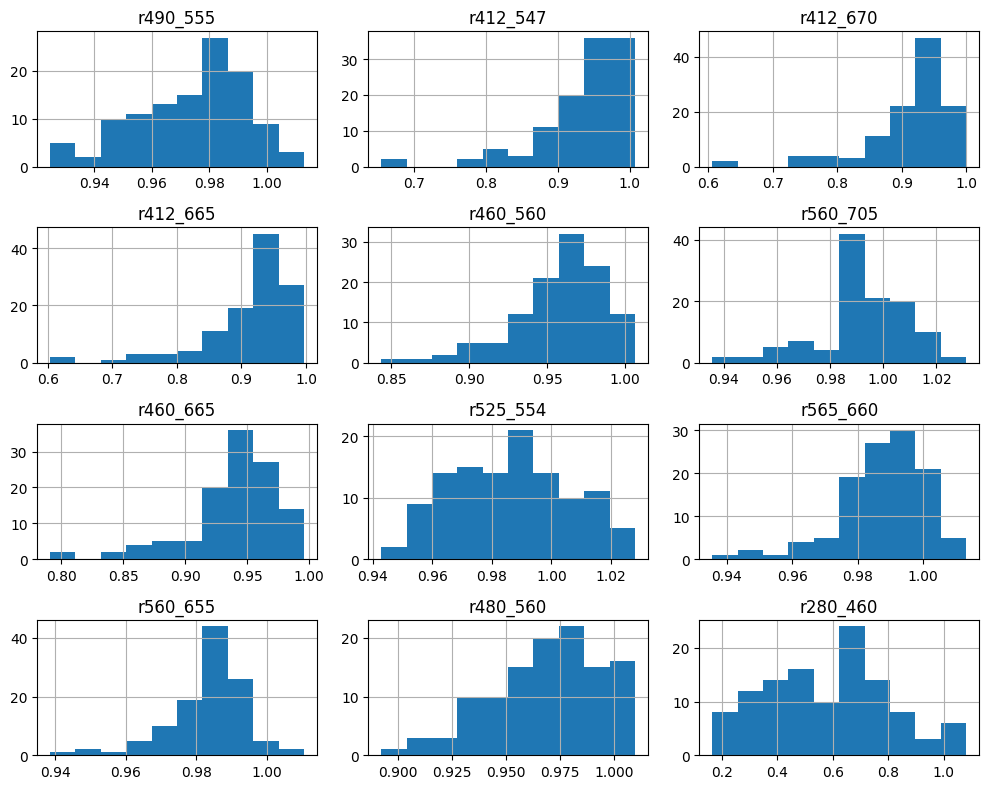

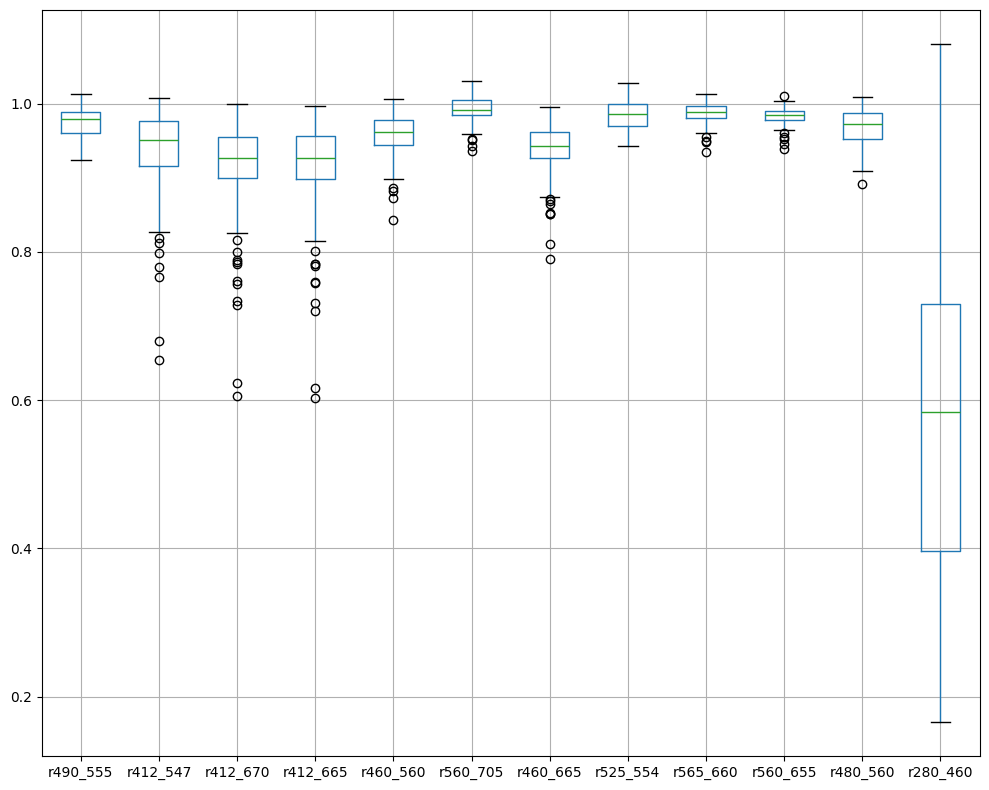

In [15]:
uv_data.hist(figsize=(10,8))
plt.tight_layout()
plt.show()
uv_data.boxplot(figsize=(10,8))
plt.tight_layout()
plt.show()


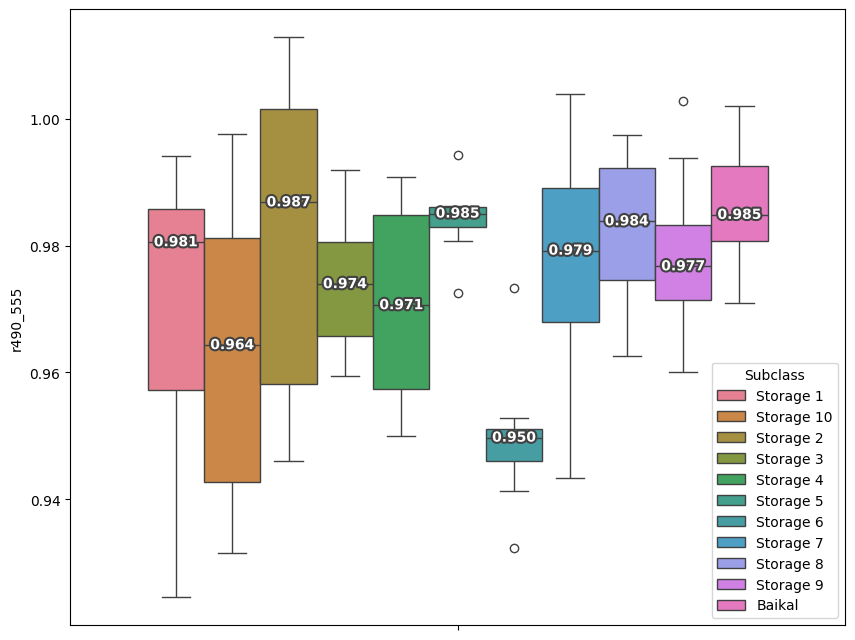

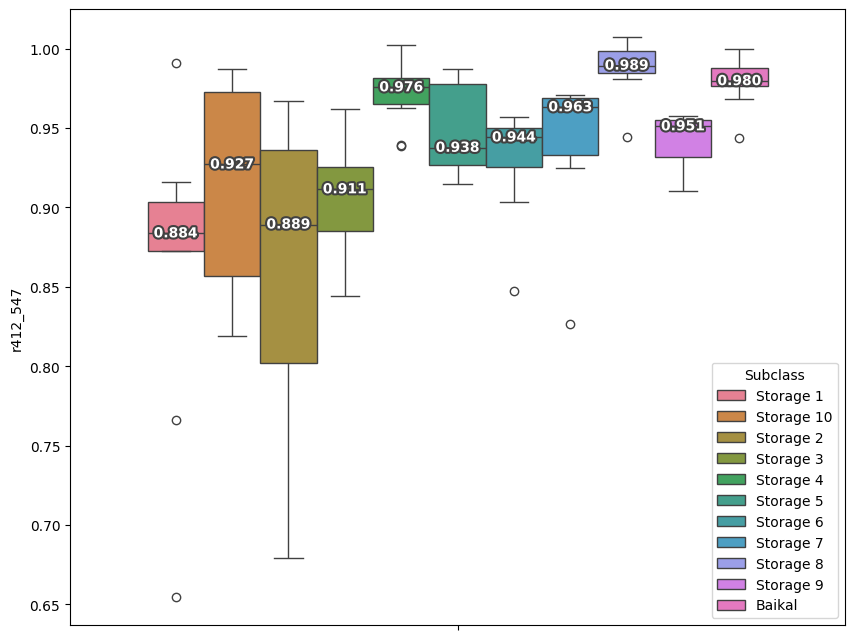

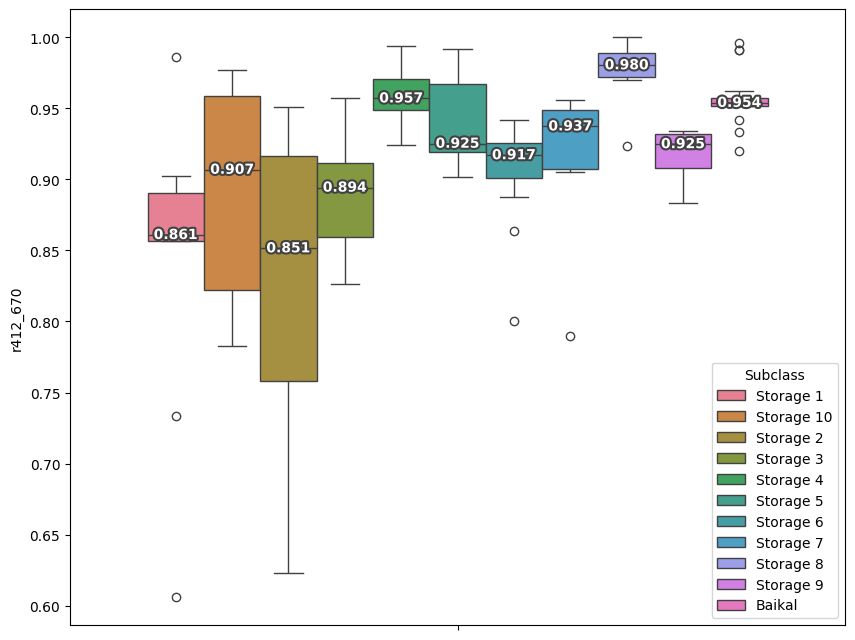

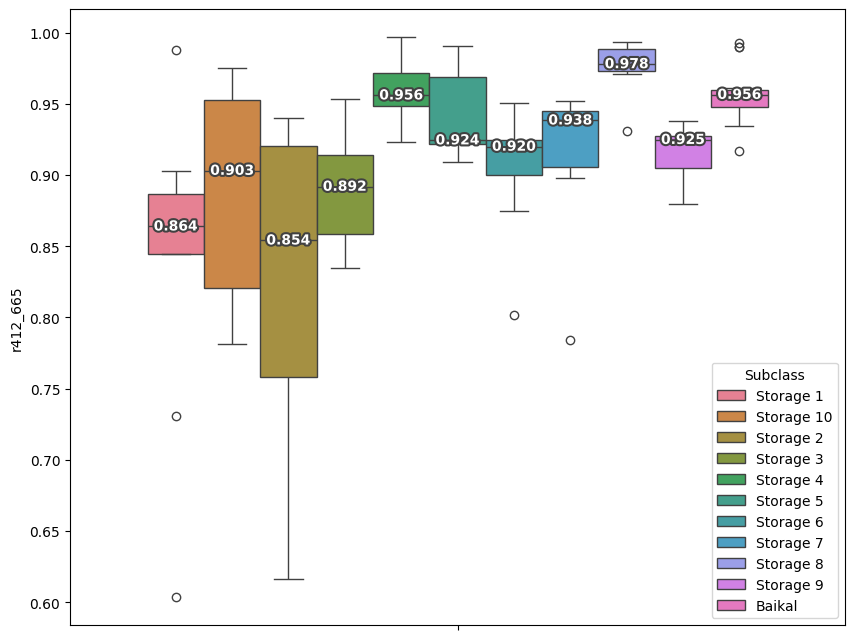

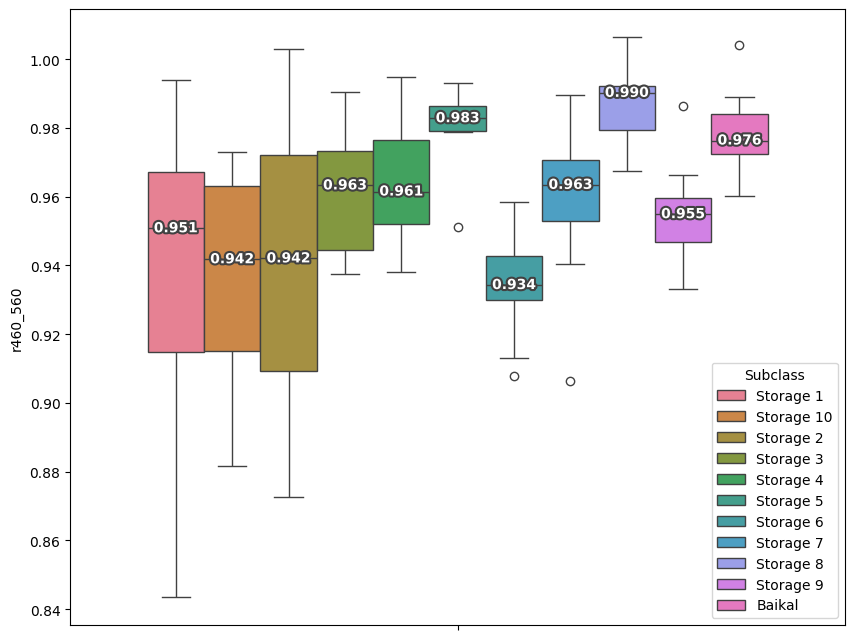

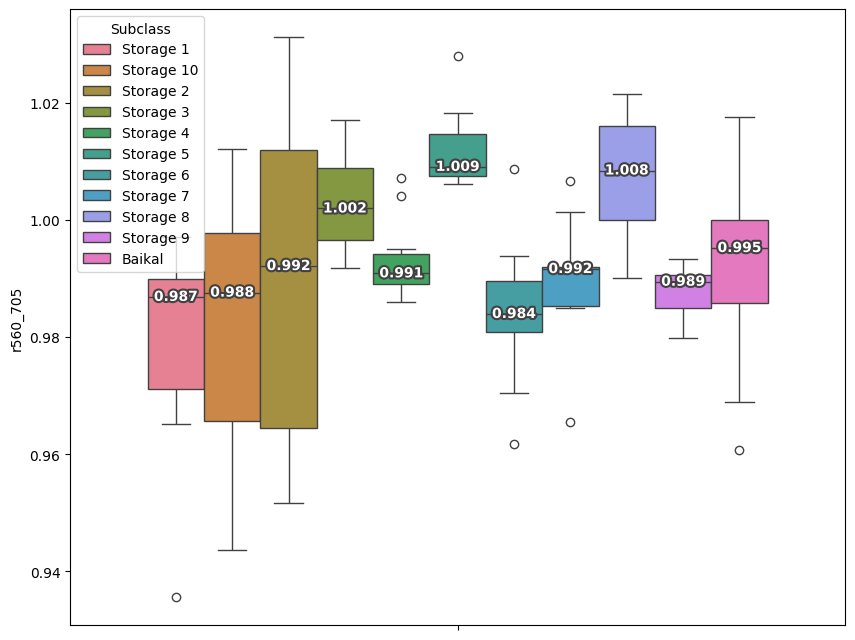

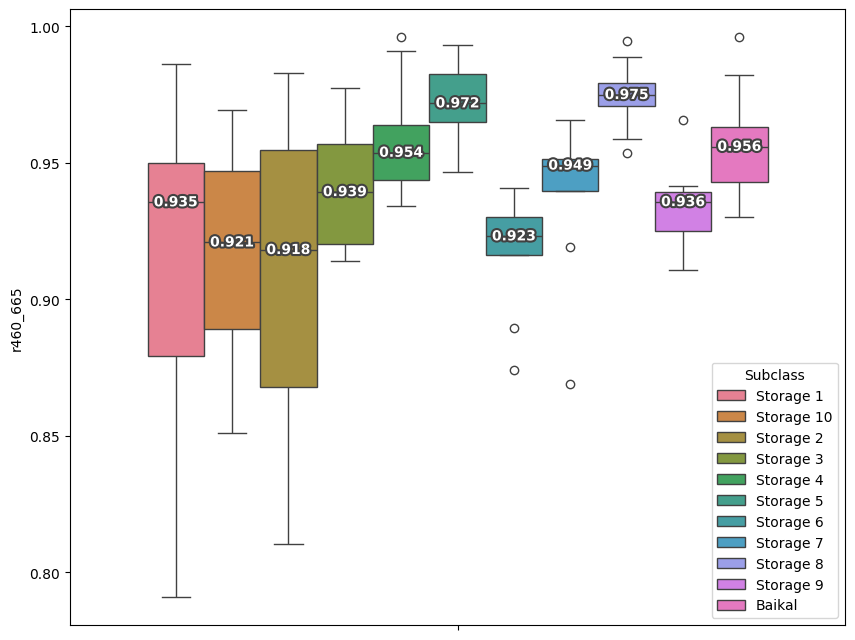

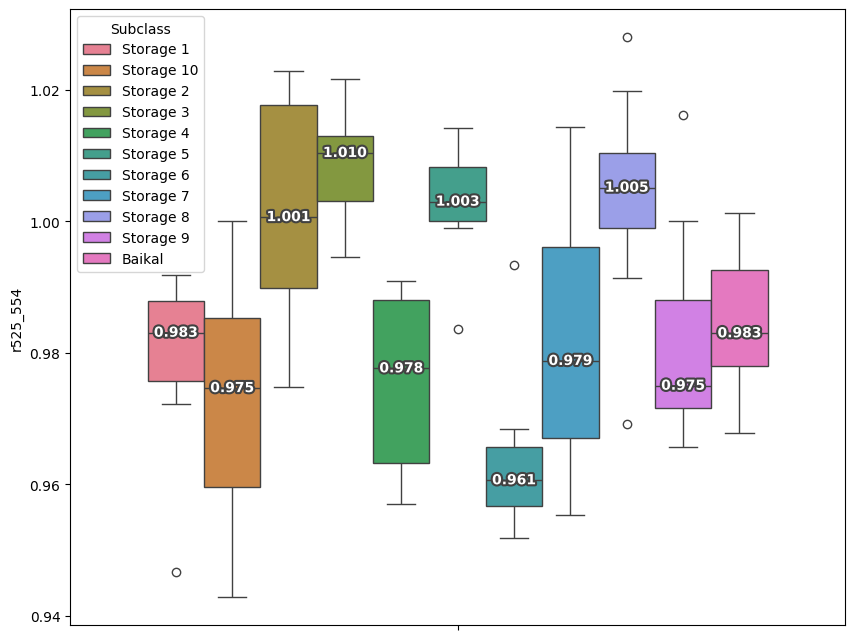

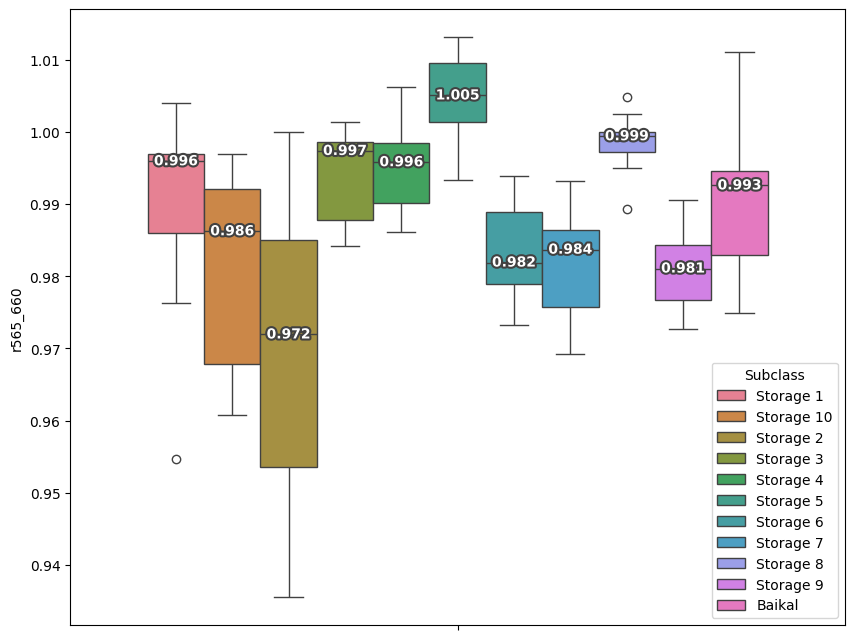

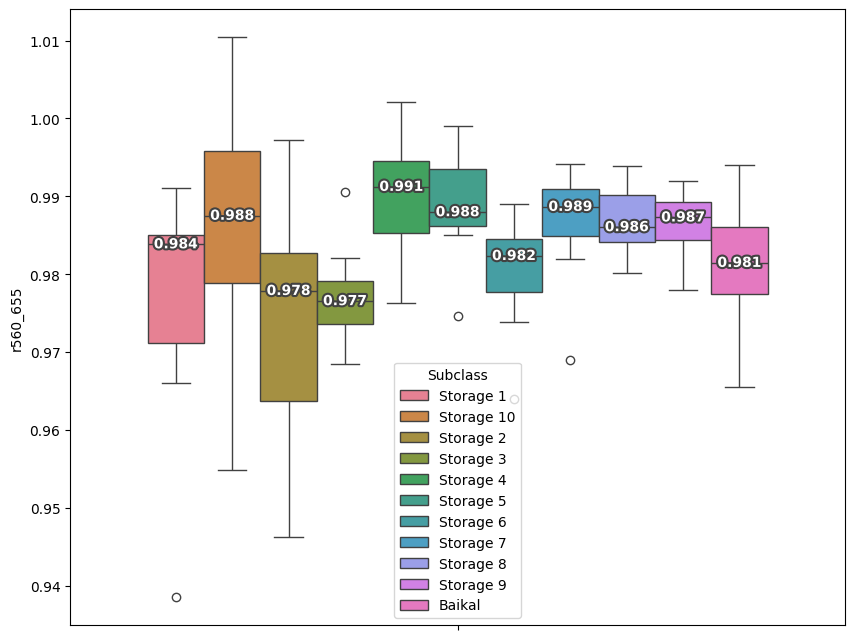

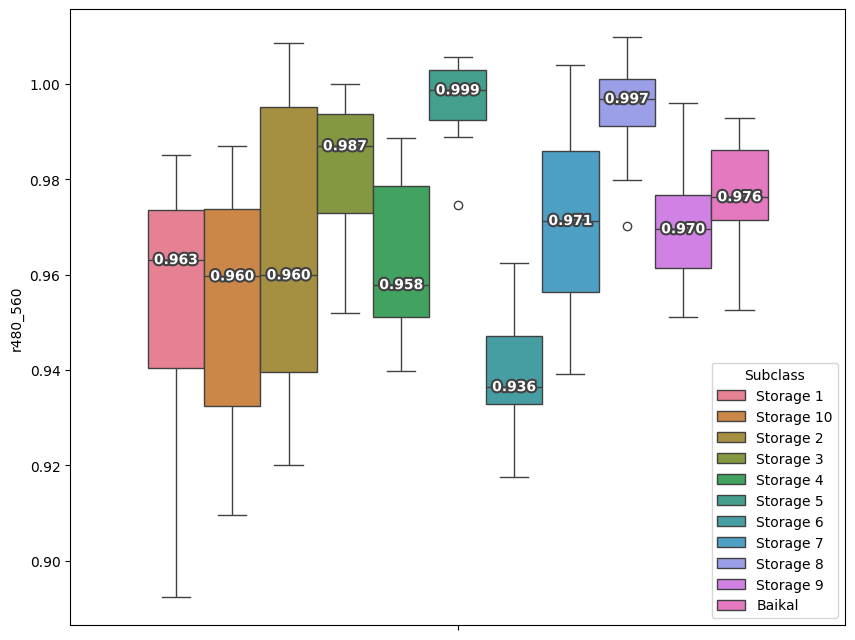

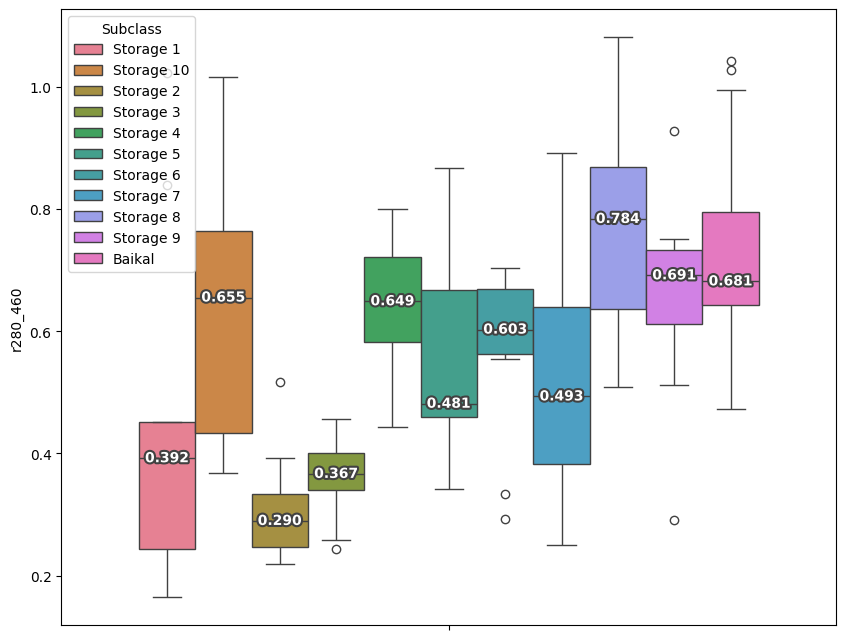

In [16]:
for feature in uv_data.columns[1:-1]:
    fig,ax = plt.subplots(1,1,figsize=(10,8))
    box = sns.boxplot(data=uv_data,y=feature,hue="Subclass",ax=ax)
    add_median_labels(box)
    plt.show()